## Practica 3

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix
import time
print(tf.__version__)

2.21.0


In [7]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [8]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


In [9]:
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

Como en la conclusión especificamos la mejor configuración y por qué nos quedábamos con ella, vamos a trabajar a partir de ese experimento.

In [10]:
# Transformamos las etiquetas originales (0-9) en etiquetas binarias: 0 para pares, 1 para imparesy_train_binary = y_train % 2
y_test_binary = y_test % 2
y_train_binary = y_train % 2
print("Primeras 10 etiquetas originales:", y_train[:10])
print("Primeras 10 etiquetas binarias (Par=0, Impar=1):", y_train_binary[:10])

Primeras 10 etiquetas originales: [5 0 4 1 9 2 1 3 1 4]
Primeras 10 etiquetas binarias (Par=0, Impar=1): [1 0 0 1 1 0 1 1 1 0]


Como ahora estamos hablando de clasificación binaria en vez de multiclase, hay que cambiar algunas cosas
(Para que sea más ameno a la hora de corregir, pongo aquí los cambios que he hecho en cada experimento):

# Índice práctica 3

1. Experimento 1: CNN Base (Filtros 3x3) (1 capa convolucional con kernel 3x3, MaxPooling y 1 capa densa) para establecer un rendimiento de referencia. los filtros más pequeños se centran en los detalles finos y generan mapas de características más grandes.   
2. Experimento 2: Profundidad y Dropout (2 capas convolucionales, MaxPooling, capa densa y Dropout). la capa de dropout se coloca tras las capas de pooling para desactivar aleatoriamente una fracción de neuronas durante el entrenamiento y prevenir el sobreajuste.   
3. Experimento 3: Red con Batch Normalization (3 capas convolucionales aplicando Batch Normalization entre la convolución y la función de activación). esto normaliza las activaciones, estabiliza el aprendizaje y acelera el entrenamiento.   
4. Experimento 4: Inspiración LeNet-5 (Kernels 5x5) (2 capas convolucionales con filtros 5x5 y Average Pooling). basado en la clásica red lenet-5 para reconocimiento de dígitos, usa filtros más grandes que capturan un contexto espacial más amplio, aunque producen mapas de características más pequeños.   
5. Experimento 5: Variación de Stride y Padding (arquitectura del experimento 2 aplicando Stride de 2 y Padding Same). probar padding 'same' asegura las mismas dimensiones entre entrada y salida, mientras que aumentar el stride reduce el tamaño del mapa perdiendo resolución espacial.   
6. Experimento 6: Entrenamiento SGD con Momentum (arquitectura del experimento 2 usando el optimizador sgd con momentum y decaimiento de pesos). esta prueba imita las estrategias de optimización clásicas de redes como alexnet para comparar su convergencia frente a adam.   
7. Experimento 7: Arquitectura Ligera (2 capas convolucionales con solo 16 y 32 filtros, Dropout bajo y capa densa reducida) para evaluar si un modelo con muchos menos parámetros puede extraer las características suficientes manteniendo buena precisión con menor coste.

## EXPERIMENTO 1

In [11]:
model_1 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [12]:
model_1.compile(optimizer='adam',
                        loss='binary_crossentropy',
                        metrics=['accuracy'])

In [13]:
inicio = time.time()
# Redimensionamos la entrada añadiendo la dimensión del canal para la capa Conv2D
h_binary = model_1.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2)
fin = time.time()

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9455 - loss: 0.1410 - val_accuracy: 0.9790 - val_loss: 0.0650
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9795 - loss: 0.0579 - val_accuracy: 0.9843 - val_loss: 0.0498
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9835 - loss: 0.0454 - val_accuracy: 0.9877 - val_loss: 0.0386
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9879 - loss: 0.0346 - val_accuracy: 0.9866 - val_loss: 0.0403
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9906 - loss: 0.0280 - val_accuracy: 0.9891 - val_loss: 0.0340


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Tiempo de entrenamiento: 15.17 segundos
Accuracy Entrenamiento: 0.9926 | Loss Entrenamiento: 0.0239
Accuracy Test: 0.9870 | Loss Test: 0.0351
Errores Train: 447 | Errores Test: 130


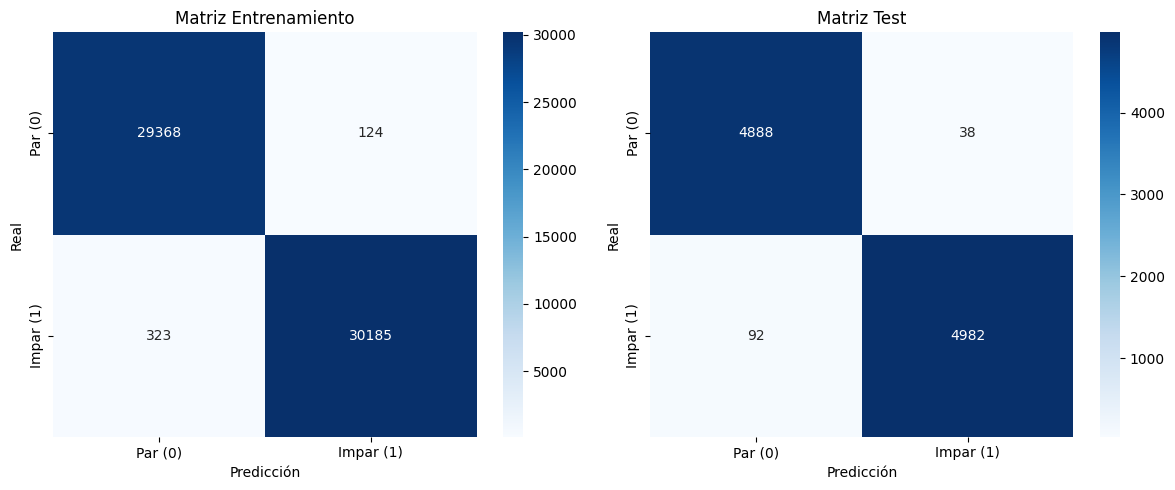

In [14]:
loss_train, acc_train = model_1.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test, acc_test = model_1.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)
tiempo_entrenamiento = fin - inicio

# Predicciones probabilísticas
y_pred_prob = model_1.predict(x_test[..., np.newaxis])
y_pred_binary = (y_pred_prob >= 0.5).astype(int).flatten()

y_pred_train_prob = model_1.predict(x_train[..., np.newaxis])
y_pred_train_binary = (y_pred_train_prob >= 0.5).astype(int).flatten()
errores_train = np.sum(y_train_binary != y_pred_train_binary)
cm_train = confusion_matrix(y_train_binary, y_pred_train_binary)

y_pred_test_prob = model_1.predict(x_test[..., np.newaxis])
y_pred_test_binary = (y_pred_test_prob >= 0.5).astype(int).flatten()
errores_test = np.sum(y_test_binary != y_pred_test_binary)
cm_test = confusion_matrix(y_test_binary, y_pred_test_binary)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train:.4f} | Loss Entrenamiento: {loss_train:.4f}")
print(f"Accuracy Test: {acc_test:.4f} | Loss Test: {loss_test:.4f}")
print(f"Errores Train: {errores_train} | Errores Test: {errores_test}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Par (0)', 'Impar (1)'],
            yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')
axes[0].set_title('Matriz Entrenamiento')

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Par (0)', 'Impar (1)'],
            yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')
axes[1].set_title('Matriz Test')

plt.tight_layout()
plt.show()

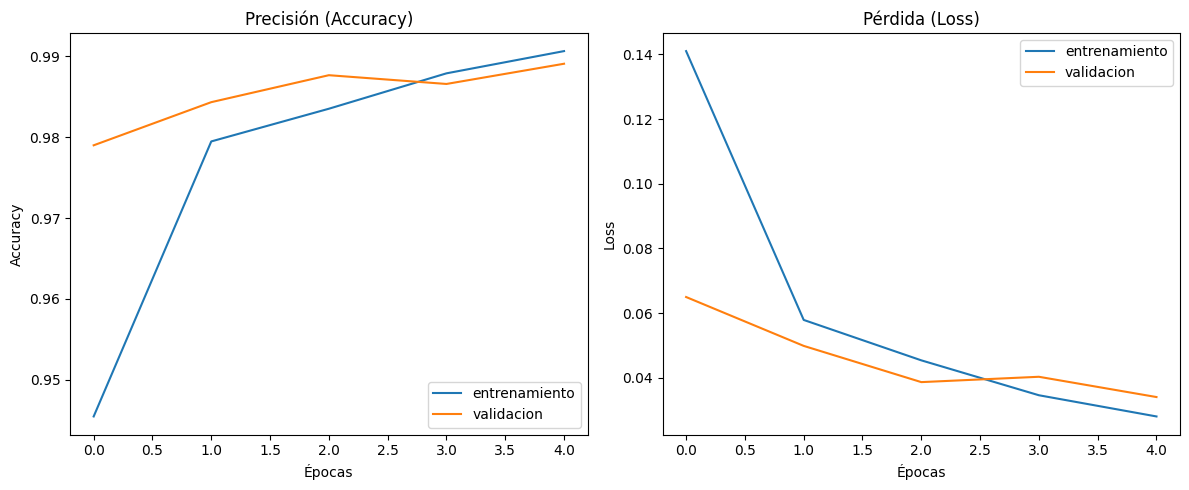

In [15]:
plt.figure(figsize=(12, 5))

# Gráfico de Accuracy
plt.subplot(1, 2, 1)
plt.plot(h_binary.history['accuracy'], label='entrenamiento')
plt.plot(h_binary.history['val_accuracy'], label='validacion')
plt.title('Precisión (Accuracy)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Gráfico de Loss
plt.subplot(1, 2, 2)
plt.plot(h_binary.history['loss'], label='entrenamiento')
plt.plot(h_binary.history['val_loss'], label='validacion')
plt.title('Pérdida (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Análisis del Experimento 1: CNN Base (Filtros 3x3)
- **Rendimiento:** Logra un excelente rendimiento de referencia con un **Accuracy de Test del 98.70%** y una pérdida de **0.0351**.
- **Convergencia:** La curva de aprendizaje muestra que el modelo aprende rápidamente desde la primera época, aunque hay una ligera brecha entre entrenamiento y validación al final, sugiriendo un inicio muy sutil de sobreajuste.
- **Errores:** Comete **130 errores en el set de test**, distribuidos de forma equilibrada entre falsos positivos y falsos negativos.

## EXPERIMENTO 2

In [19]:
# Definición del modelo 2
model_2 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_2.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_2 = model_2.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_2 = fin - inicio

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9293 - loss: 0.1775 - val_accuracy: 0.9816 - val_loss: 0.0563
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9759 - loss: 0.0689 - val_accuracy: 0.9868 - val_loss: 0.0394
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9820 - loss: 0.0520 - val_accuracy: 0.9898 - val_loss: 0.0330
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9847 - loss: 0.0436 - val_accuracy: 0.9921 - val_loss: 0.0271
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9873 - loss: 0.0370 - val_accuracy: 0.9919 - val_loss: 0.0256


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Tiempo de entrenamiento: 15.43 segundos
Accuracy Entrenamiento: 0.9939 | Loss Entrenamiento: 0.0190
Accuracy Test: 0.9940 | Loss Test: 0.0196
Errores Train: 366 | Errores Test: 60


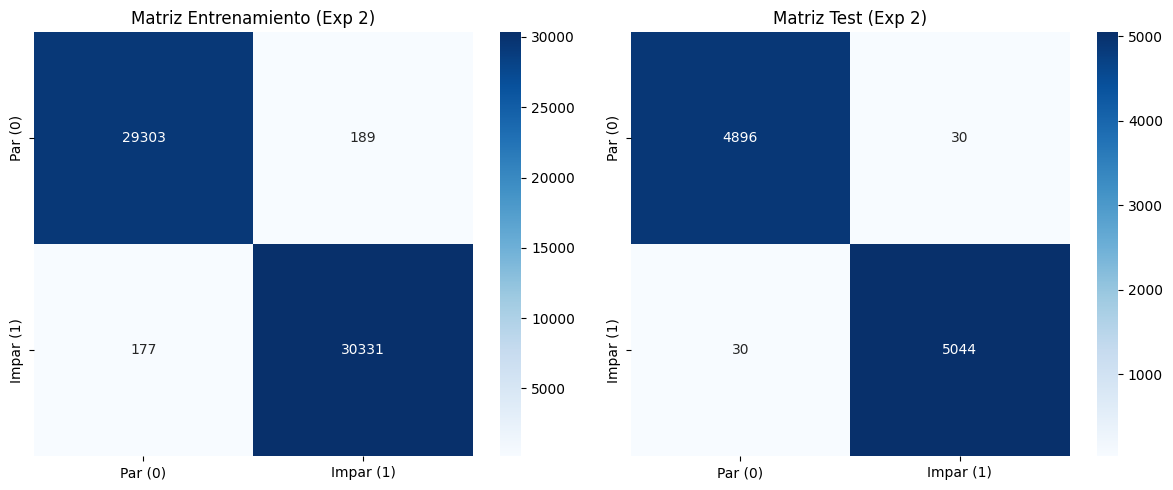

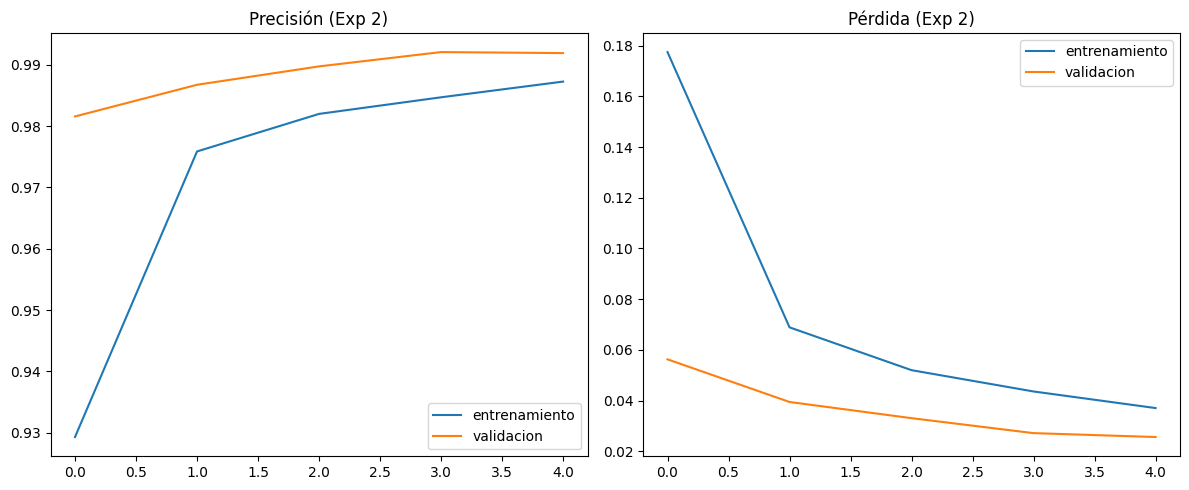

In [20]:
# Evaluación y métricas
loss_train_2, acc_train_2 = model_2.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_2, acc_test_2 = model_2.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_2 = model_2.predict(x_train[..., np.newaxis])
y_pred_train_binary_2 = (y_pred_train_prob_2 >= 0.5).astype(int).flatten()
errores_train_2 = np.sum(y_train_binary != y_pred_train_binary_2)
cm_train_2 = confusion_matrix(y_train_binary, y_pred_train_binary_2)

y_pred_test_prob_2 = model_2.predict(x_test[..., np.newaxis])
y_pred_test_binary_2 = (y_pred_test_prob_2 >= 0.5).astype(int).flatten()
errores_test_2 = np.sum(y_test_binary != y_pred_test_binary_2)
cm_test_2 = confusion_matrix(y_test_binary, y_pred_test_binary_2)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_2:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_2:.4f} | Loss Entrenamiento: {loss_train_2:.4f}")
print(f"Accuracy Test: {acc_test_2:.4f} | Loss Test: {loss_test_2:.4f}")
print(f"Errores Train: {errores_train_2} | Errores Test: {errores_test_2}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_2, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 2)')
sns.heatmap(cm_test_2, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 2)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_2.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_2.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 2)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_2.history['loss'], label='entrenamiento')
plt.plot(h_binary_2.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 2)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 2: Profundidad y Dropout
- **Rendimiento:** Es el modelo con más **Accuracy de Test del 99.40%** y la menor pérdida de **0.0196**.
- **Convergencia:** El uso de dos capas convolucionales junto con el Dropout reduce drásticamente el sobreajuste. Las curvas de entrenamiento y validación progresan de forma muy unida y estable.
- **Eficiencia y Errores:** Se entrena en tan solo **15.43 segundos** y reduce los errores en test a únicamente **60 fallos**, demostrando el impacto positivo de la regularización.

## EXPERIMENTO 3

In [21]:
# Definición del modelo 3
model_3 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_3.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_3 = model_3.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_3 = fin - inicio

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9789 - loss: 0.0570 - val_accuracy: 0.5048 - val_loss: 2.4215
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9923 - loss: 0.0223 - val_accuracy: 0.9877 - val_loss: 0.0383
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9947 - loss: 0.0147 - val_accuracy: 0.9919 - val_loss: 0.0273
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9963 - loss: 0.0104 - val_accuracy: 0.9879 - val_loss: 0.0386
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9972 - loss: 0.0084 - val_accuracy: 0.9898 - val_loss: 0.0378


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Tiempo de entrenamiento: 17.03 segundos
Accuracy Entrenamiento: 0.9931 | Loss Entrenamiento: 0.0202
Accuracy Test: 0.9894 | Loss Test: 0.0329
Errores Train: 416 | Errores Test: 106


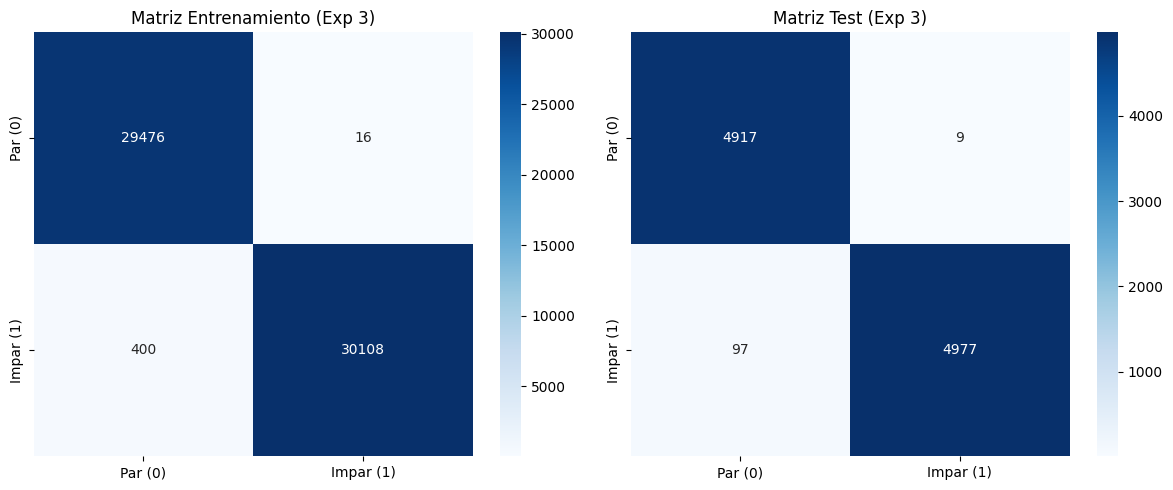

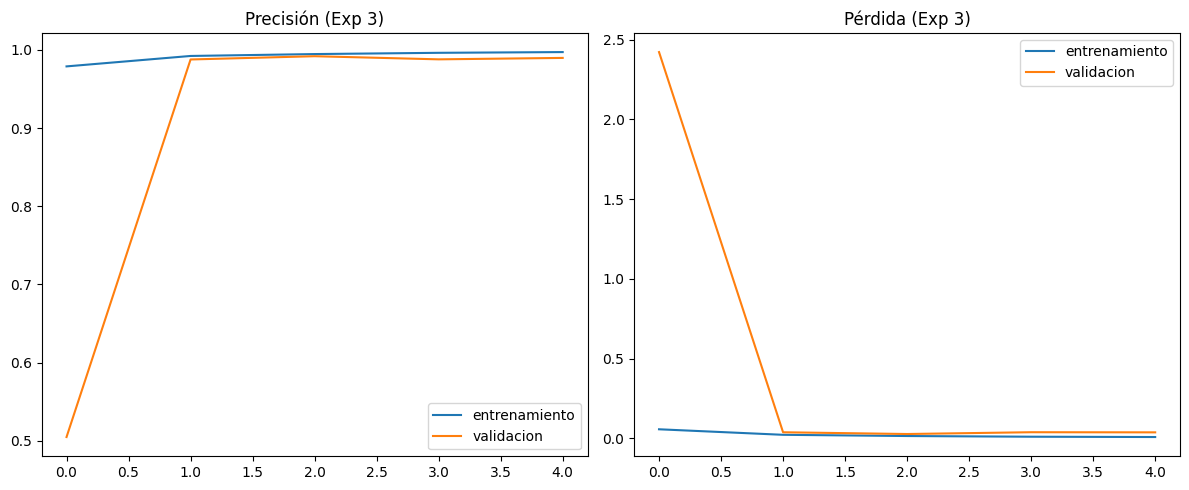

In [22]:
# Evaluación y métricas
loss_train_3, acc_train_3 = model_3.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_3, acc_test_3 = model_3.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_3 = model_3.predict(x_train[..., np.newaxis])
y_pred_train_binary_3 = (y_pred_train_prob_3 >= 0.5).astype(int).flatten()
errores_train_3 = np.sum(y_train_binary != y_pred_train_binary_3)
cm_train_3 = confusion_matrix(y_train_binary, y_pred_train_binary_3)

y_pred_test_prob_3 = model_3.predict(x_test[..., np.newaxis])
y_pred_test_binary_3 = (y_pred_test_prob_3 >= 0.5).astype(int).flatten()
errores_test_3 = np.sum(y_test_binary != y_pred_test_binary_3)
cm_test_3 = confusion_matrix(y_test_binary, y_pred_test_binary_3)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_3:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_3:.4f} | Loss Entrenamiento: {loss_train_3:.4f}")
print(f"Accuracy Test: {acc_test_3:.4f} | Loss Test: {loss_test_3:.4f}")
print(f"Errores Train: {errores_train_3} | Errores Test: {errores_test_3}")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_3, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 3)')
sns.heatmap(cm_test_3, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 3)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_3.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_3.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 3)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_3.history['loss'], label='entrenamiento')
plt.plot(h_binary_3.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 3)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 3: Batch Normalization
- **Rendimiento:** Alcanza un **Accuracy de Test del 98.94%** y una pérdida de **0.0329**.
- **Particularidad:** Al iniciar el entrenamiento con Batch Normalization sin regularización adicional como Dropout, la validación en la primera época es inestable, pero se estabiliza de inmediato logrando una precisión casi perfecta en entrenamiento (99.72%).
- **Errores:** Presenta **106 errores en test**. Muestra una ligera tendencia al sobreajuste debido a la alta capacidad de memorización que induce la normalización en una arquitectura de 3 capas sin Dropout.

## EXPERIMENTO 4

In [23]:
# Definición del modelo 4
model_4 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(6, (5, 5), activation='tanh', padding='same'),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Conv2D(16, (5, 5), activation='tanh'),
    tf.keras.layers.AveragePooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(120, activation='tanh'),
    tf.keras.layers.Dense(84, activation='tanh'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_4.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_4 = model_4.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_4 = fin - inicio

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9126 - loss: 0.2125 - val_accuracy: 0.9672 - val_loss: 0.0914
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9730 - loss: 0.0763 - val_accuracy: 0.9787 - val_loss: 0.0619
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9811 - loss: 0.0546 - val_accuracy: 0.9828 - val_loss: 0.0475
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9852 - loss: 0.0414 - val_accuracy: 0.9851 - val_loss: 0.0440
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9884 - loss: 0.0340 - val_accuracy: 0.9860 - val_loss: 0.0421


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Tiempo de entrenamiento: 16.18 segundos
Accuracy Entrenamiento: 0.9897 | Loss Entrenamiento: 0.0296
Accuracy Test: 0.9884 | Loss Test: 0.0324
Errores Train: 616 | Errores Test: 116


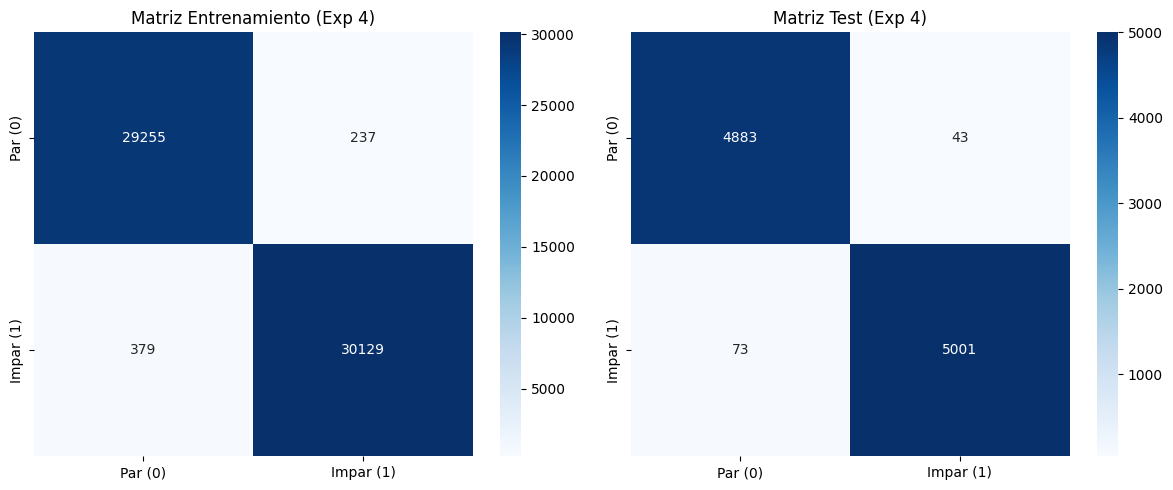

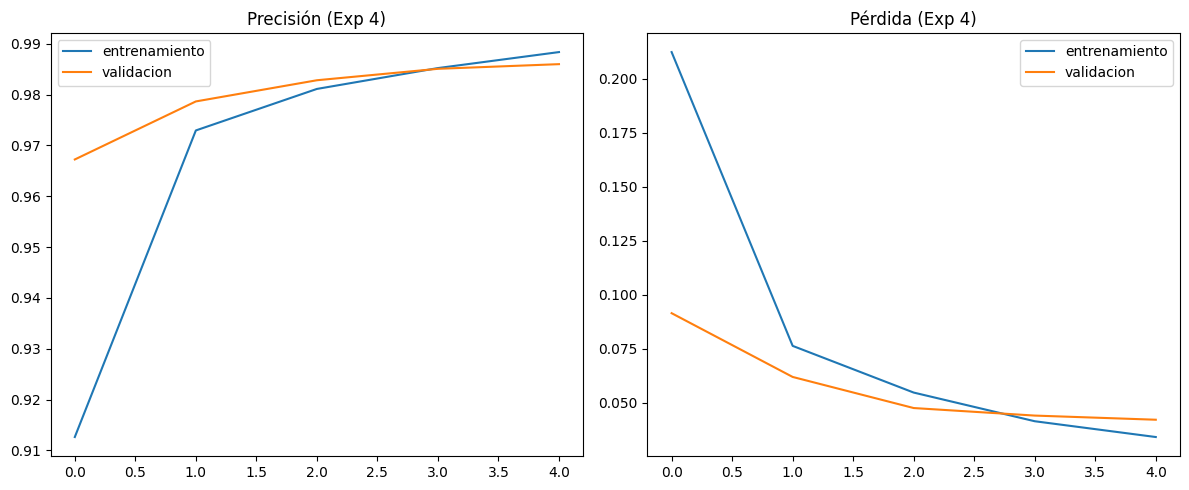

In [24]:
# Evaluación y métricas
loss_train_4, acc_train_4 = model_4.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_4, acc_test_4 = model_4.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_4 = model_4.predict(x_train[..., np.newaxis])
y_pred_train_binary_4 = (y_pred_train_prob_4 >= 0.5).astype(int).flatten()
errores_train_4 = np.sum(y_train_binary != y_pred_train_binary_4)
cm_train_4 = confusion_matrix(y_train_binary, y_pred_train_binary_4)

y_pred_test_prob_4 = model_4.predict(x_test[..., np.newaxis])
y_pred_test_binary_4 = (y_pred_test_prob_4 >= 0.5).astype(int).flatten()
errores_test_4 = np.sum(y_test_binary != y_pred_test_binary_4)
cm_test_4 = confusion_matrix(y_test_binary, y_pred_test_binary_4)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_4:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_4:.4f} | Loss Entrenamiento: {loss_train_4:.4f}")
print(f"Accuracy Test: {acc_test_4:.4f} | Loss Test: {loss_test_4:.4f}")
print(f"Errores Train: {errores_train_4} | Errores Test: {errores_test_4}")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_4, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 4)')
sns.heatmap(cm_test_4, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 4)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_4.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_4.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 4)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_4.history['loss'], label='entrenamiento')
plt.plot(h_binary_4.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 4)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 4: Inspiración LeNet-5 (Kernels 5x5)
- **Rendimiento:** Obtiene un **Accuracy de Test del 98.84%** y una pérdida de **0.0324**.
- **Convergencia:** El uso de funciones de activación `tanh` junto con filtros de 5x5 y Average Pooling genera curvas de aprendizaje suaves y progresivas.
- **Errores:** Registra **116 errores en test**. Aunque los kernels de mayor tamaño capturan mayor contexto espacial, la arquitectura clásica LeNet-5 parece ser menos precisa que la combinación del Experimento 2.

## EXPERIMENTO 5

In [25]:
# Definición del modelo 5
model_5 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), strides=2, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), strides=2, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_5.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_5 = model_5.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_5 = fin - inicio

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8751 - loss: 0.2852 - val_accuracy: 0.9678 - val_loss: 0.0910
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9556 - loss: 0.1247 - val_accuracy: 0.9768 - val_loss: 0.0645
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9669 - loss: 0.0943 - val_accuracy: 0.9813 - val_loss: 0.0536
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9709 - loss: 0.0817 - val_accuracy: 0.9834 - val_loss: 0.0476
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9743 - loss: 0.0727 - val_accuracy: 0.9842 - val_loss: 0.0464


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Tiempo de entrenamiento: 16.05 segundos
Accuracy Entrenamiento: 0.9860 | Loss Entrenamiento: 0.0419
Accuracy Test: 0.9867 | Loss Test: 0.0399
Errores Train: 841 | Errores Test: 133


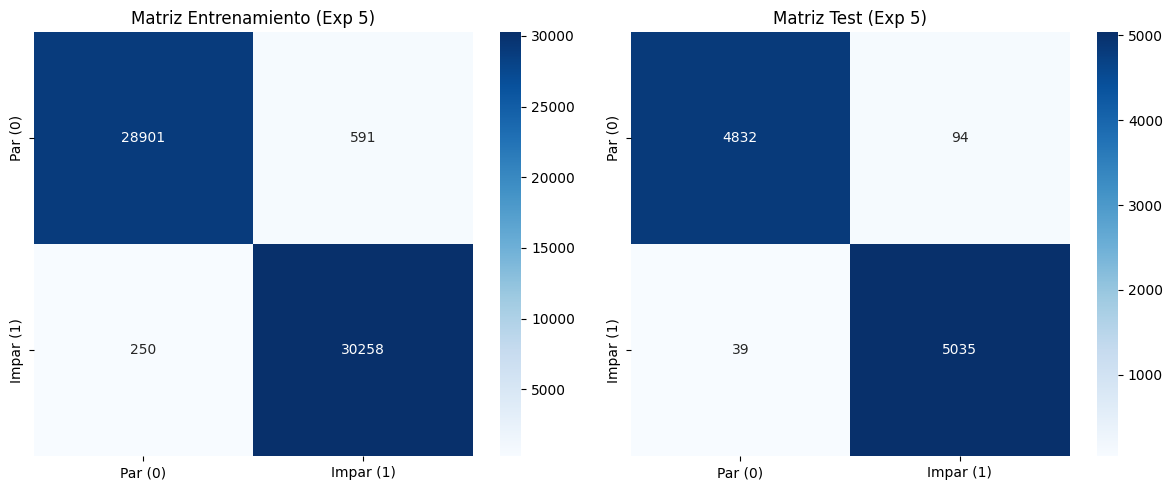

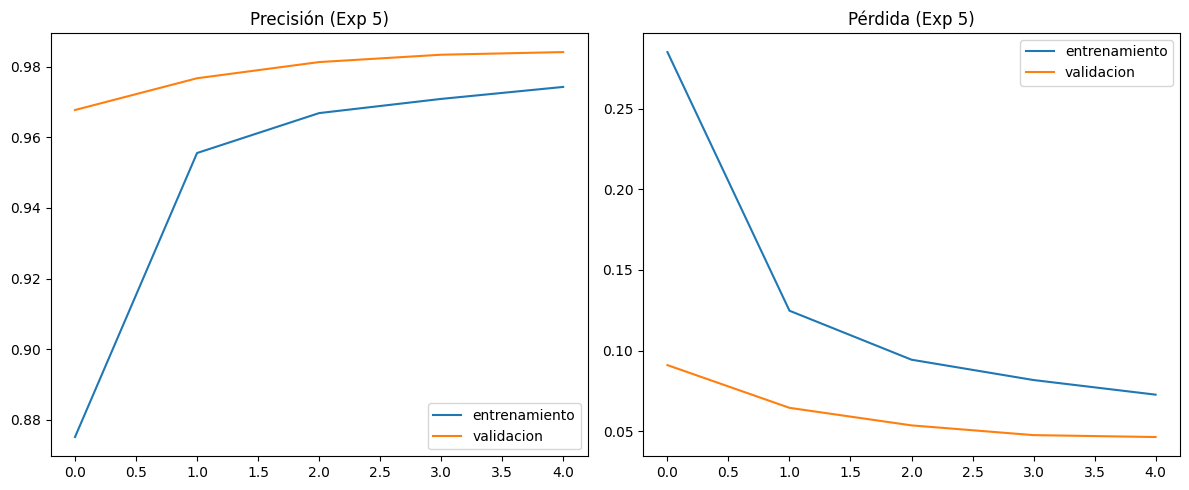

In [26]:
# Evaluación y métricas
loss_train_5, acc_train_5 = model_5.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_5, acc_test_5 = model_5.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_5 = model_5.predict(x_train[..., np.newaxis])
y_pred_train_binary_5 = (y_pred_train_prob_5 >= 0.5).astype(int).flatten()
errores_train_5 = np.sum(y_train_binary != y_pred_train_binary_5)
cm_train_5 = confusion_matrix(y_train_binary, y_pred_train_binary_5)

y_pred_test_prob_5 = model_5.predict(x_test[..., np.newaxis])
y_pred_test_binary_5 = (y_pred_test_prob_5 >= 0.5).astype(int).flatten()
errores_test_5 = np.sum(y_test_binary != y_pred_test_binary_5)
cm_test_5 = confusion_matrix(y_test_binary, y_pred_test_binary_5)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_5:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_5:.4f} | Loss Entrenamiento: {loss_train_5:.4f}")
print(f"Accuracy Test: {acc_test_5:.4f} | Loss Test: {loss_test_5:.4f}")
print(f"Errores Train: {errores_train_5} | Errores Test: {errores_test_5}")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_5, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 5)')
sns.heatmap(cm_test_5, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 5)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_5.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_5.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 5)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_5.history['loss'], label='entrenamiento')
plt.plot(h_binary_5.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 5)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 5: Variación de Stride y Padding
- **Rendimiento:** Registra un **Accuracy de Test del 98.67%** y una pérdida de **0.0399**.
- **Efecto de la reducción dimensional:** Al configurar un stride de 2, el tamaño de los mapas de características disminuye de forma acelerada. Esto hace que haya menos carga computacional, pero provoca una pérdida de resolución espacial (menor precisión).
- **Errores:** Presenta **133 errores en test**, el número más alto junto con el modelo base, confirmando que la pérdida de detalle afectó la clasificación.

## EXPERIMENTO 6

In [27]:
# Definición del modelo 6
model_6 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

sgd_optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, decay=1e-6)

model_6.compile(optimizer=sgd_optimizer,
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_6 = model_6.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_6 = fin - inicio

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8471 - loss: 0.3393 - val_accuracy: 0.9578 - val_loss: 0.1299
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9467 - loss: 0.1458 - val_accuracy: 0.9761 - val_loss: 0.0715
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9645 - loss: 0.1002 - val_accuracy: 0.9797 - val_loss: 0.0536
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9712 - loss: 0.0841 - val_accuracy: 0.9843 - val_loss: 0.0461
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9756 - loss: 0.0707 - val_accuracy: 0.9861 - val_loss: 0.0393


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Tiempo de entrenamiento: 19.36 segundos
Accuracy Entrenamiento: 0.9862 | Loss Entrenamiento: 0.0393
Accuracy Test: 0.9879 | Loss Test: 0.0344
Errores Train: 830 | Errores Test: 121


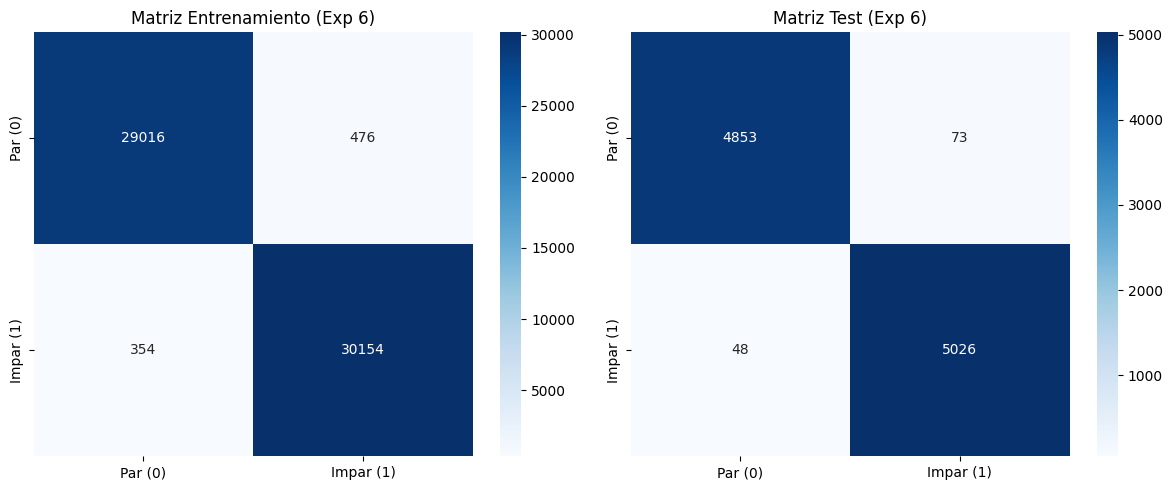

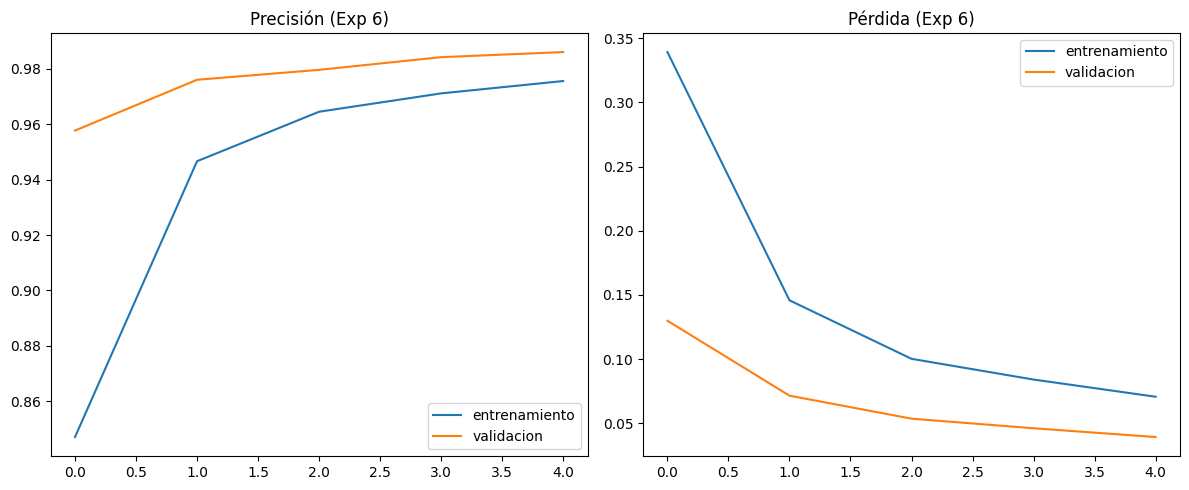

In [28]:
# Evaluación y métricas
loss_train_6, acc_train_6 = model_6.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_6, acc_test_6 = model_6.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_6 = model_6.predict(x_train[..., np.newaxis])
y_pred_train_binary_6 = (y_pred_train_prob_6 >= 0.5).astype(int).flatten()
errores_train_6 = np.sum(y_train_binary != y_pred_train_binary_6)
cm_train_6 = confusion_matrix(y_train_binary, y_pred_train_binary_6)

y_pred_test_prob_6 = model_6.predict(x_test[..., np.newaxis])
y_pred_test_binary_6 = (y_pred_test_prob_6 >= 0.5).astype(int).flatten()
errores_test_6 = np.sum(y_test_binary != y_pred_test_binary_6)
cm_test_6 = confusion_matrix(y_test_binary, y_pred_test_binary_6)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_6:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_6:.4f} | Loss Entrenamiento: {loss_train_6:.4f}")
print(f"Accuracy Test: {acc_test_6:.4f} | Loss Test: {loss_test_6:.4f}")
print(f"Errores Train: {errores_train_6} | Errores Test: {errores_test_6}")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_6, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 6)')
sns.heatmap(cm_test_6, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 6)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_6.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_6.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 6)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_6.history['loss'], label='entrenamiento')
plt.plot(h_binary_6.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 6)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 6: Entrenamiento SGD con Momentum
- **Rendimiento:** Consigue un **Accuracy de Test del 98.79%** y una pérdida de **0.0344**.
- **Dinámica de Optimización:** A diferencia de Adam, SGD con Momentum converge de manera más pausada. En la primera época la precisión es menor (84.71%), pero logra recuperarse por la quinta época.
- **Errores:** Finaliza con **121 errores en test**. Demuestra que SGD con momentum es una alternativa sólida, aunque requiere un ajuste de hiperparámetros más detallado y suele tardar más en optimizar (19.36 s).

## EXPERIMENTO 7

In [29]:
# Definición del modelo 7
model_7 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.1),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.1),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_7.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

# Entrenamiento
inicio = time.time()
h_binary_7 = model_7.fit(x_train[..., np.newaxis], y_train_binary, epochs=5, batch_size=128, validation_split=0.2, verbose=1)
fin = time.time()
tiempo_entrenamiento_7 = fin - inicio

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9058 - loss: 0.2316 - val_accuracy: 0.9714 - val_loss: 0.0872
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9654 - loss: 0.0988 - val_accuracy: 0.9810 - val_loss: 0.0564
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9751 - loss: 0.0725 - val_accuracy: 0.9840 - val_loss: 0.0460
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9780 - loss: 0.0630 - val_accuracy: 0.9880 - val_loss: 0.0372
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9829 - loss: 0.0525 - val_accuracy: 0.9875 - val_loss: 0.0374


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Tiempo de entrenamiento: 17.99 segundos
Accuracy Entrenamiento: 0.9881 | Loss Entrenamiento: 0.0359
Accuracy Test: 0.9885 | Loss Test: 0.0363
Errores Train: 715 | Errores Test: 115


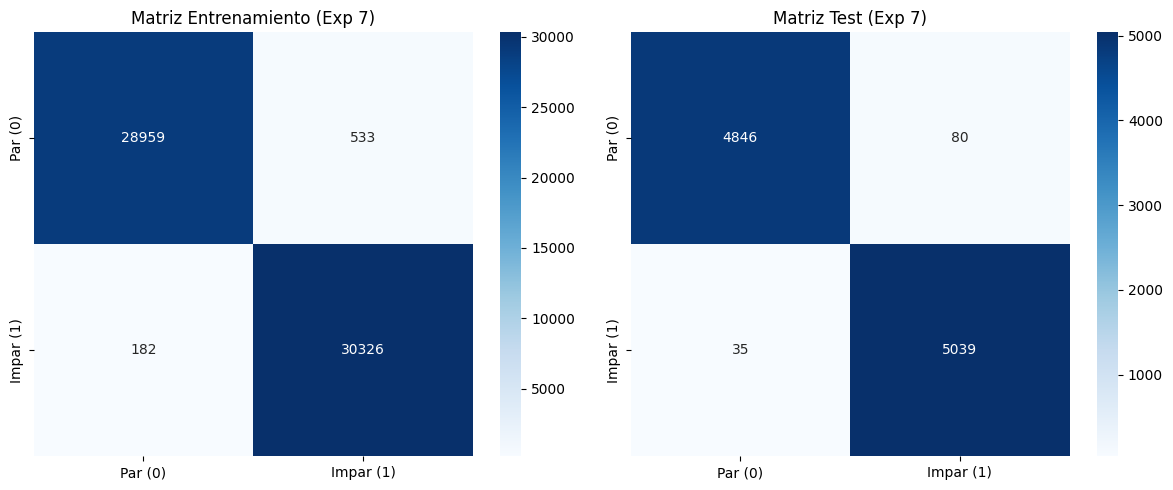

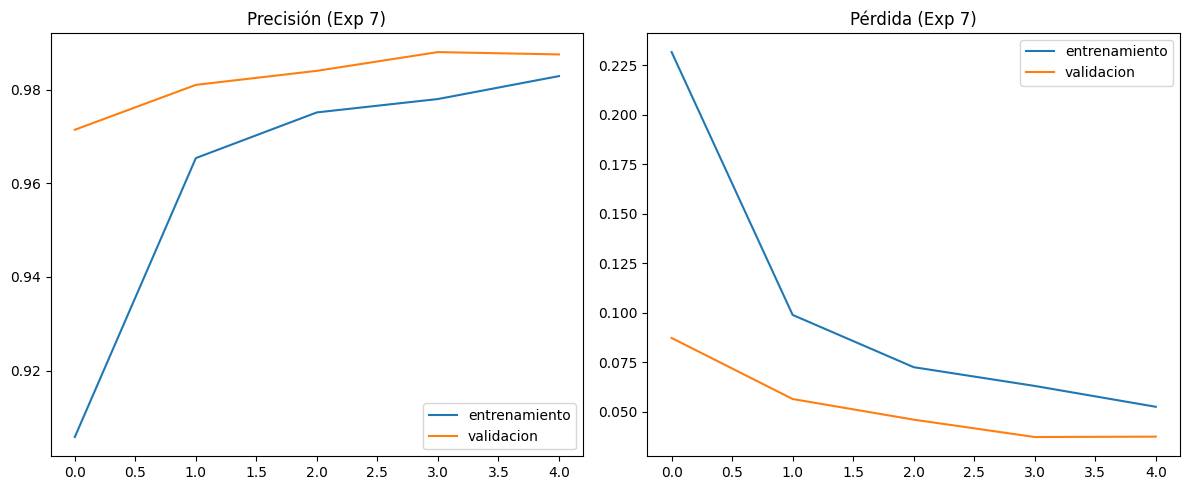

In [30]:
# Evaluación y métricas
loss_train_7, acc_train_7 = model_7.evaluate(x_train[..., np.newaxis], y_train_binary, verbose=0)
loss_test_7, acc_test_7 = model_7.evaluate(x_test[..., np.newaxis], y_test_binary, verbose=0)

y_pred_train_prob_7 = model_7.predict(x_train[..., np.newaxis])
y_pred_train_binary_7 = (y_pred_train_prob_7 >= 0.5).astype(int).flatten()
errores_train_7 = np.sum(y_train_binary != y_pred_train_binary_7)
cm_train_7 = confusion_matrix(y_train_binary, y_pred_train_binary_7)

y_pred_test_prob_7 = model_7.predict(x_test[..., np.newaxis])
y_pred_test_binary_7 = (y_pred_test_prob_7 >= 0.5).astype(int).flatten()
errores_test_7 = np.sum(y_test_binary != y_pred_test_binary_7)
cm_test_7 = confusion_matrix(y_test_binary, y_pred_test_binary_7)

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento_7:.2f} segundos")
print(f"Accuracy Entrenamiento: {acc_train_7:.4f} | Loss Entrenamiento: {loss_train_7:.4f}")
print(f"Accuracy Test: {acc_test_7:.4f} | Loss Test: {loss_test_7:.4f}")
print(f"Errores Train: {errores_train_7} | Errores Test: {errores_test_7}")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_train_7, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[0])
axes[0].set_title('Matriz Entrenamiento (Exp 7)')
sns.heatmap(cm_test_7, annot=True, fmt='d', cmap='Blues', xticklabels=['Par (0)', 'Impar (1)'], yticklabels=['Par (0)', 'Impar (1)'], ax=axes[1])
axes[1].set_title('Matriz Test (Exp 7)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h_binary_7.history['accuracy'], label='entrenamiento')
plt.plot(h_binary_7.history['val_accuracy'], label='validacion')
plt.title('Precisión (Exp 7)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h_binary_7.history['loss'], label='entrenamiento')
plt.plot(h_binary_7.history['val_loss'], label='validacion')
plt.title('Pérdida (Exp 7)')
plt.legend()
plt.tight_layout()
plt.show()

### Análisis del Experimento 7: Arquitectura Ligera
- **Rendimiento:** Consigue un gran **Accuracy de Test del 98.85%** y una pérdida de **0.0363**.
- **Eficiencia de Parámetros:** Con solo 16 y 32 filtros y una capa densa reducida (32 neuronas), el modelo es capaz de extraer casi toda la información necesaria para distinguir números pares de impares.
- **Errores:** Con tan solo **115 errores en test**, con este modelo podemos ver que para hacer tareas de complejidad binaria moderada, una red ligera es bastante buena y previene el sobreajuste de forma natural.

### Conclusión:

El Experimento 2 (Profundidad y Dropout) es el mejor modelo al alcanzar la mayor precisión en test (99.40%) y la menor pérdida (0.0196), demostrando que la profundidad junto con el Dropout previene eficazmente el sobreajuste. Además, se entrena de forma muy eficiente en solo 15.43 segundos, superando en equilibrio a arquitecturas más complejas o pesadas.

In [31]:
model_2.save('mejor_modelo_practica3_mnist.keras')